# Fig 3 · Whole-tile search

**Run first:** `R0_index_cache` → `R2_whole_tile` (accuracy, band, memory) and `R4_timing` (whole-tile timings).
Login node, spindle_env (the figure font); seconds.

* **A** Search time per query (search only): whole-matrix scan, Spindle-naive and Spindle, plus the query's own logs and the speed-ups.
* **B** Spindle NX at 5 % of N (g = 0.25), mean ± s.d. over seeds 0–4; rows aligned with A.
* **C** The typical breast query: exact d_B of every index tile (grey) and of the tiles Spindle returned.
* **D** Memory against fidelity, breast and brain: Spindle against d_B; PCA + flat and PCA-256 + PQ against d_W; the Spindle-naive and whole-matrix stores as dotted lines.

Writes `figures/fig3_whole_tile/panels/{A,B,C,D}.{pdf,png}` and `figures/fig3_whole_tile/fig3_whole_tile.{pdf,png}`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.transforms import blended_transform_factory

import style as ps
import whole_tile as wt

FIG = "fig3_whole_tile"
RES = ROOT / "results" / "whole_tile"
TIMING = ROOT / "results" / "timing" / "whole_tile.csv"
KEYS = ps.DATASET_ORDER
G = 0.25
SPINDLE, NAIVE, WHOLE = ps.TIER_COLORS["spindle"], ps.TIER_COLORS["naive"], ps.TIER_COLORS["whole"]
COMP = {"pca_flat": "#117733", "pca256_pq": "#999933"}
COMP_LABEL = {"pca_flat": "PCA + flat (whole matrix)", "pca256_pq": "PCA-256 + PQ (whole matrix)"}
ROW_BOTTOM, ROW_TOP = 21.0, 5.0      # mm: A and B share them, so their dataset rows line up
W_A, W_B, H_AB = 110.0, 70.0, 84.0
W_C, W_D, H_CD = 60.0, 120.0, 64.0

_, timing = wt.timing_tables(pd.read_csv(TIMING))
timing = timing.set_index("key")
nx = pd.read_csv(RES / "nx.csv")
memory = pd.read_csv(RES / "memory.csv", dtype={"param": str})


def ax_mm(fig, x, y, w, h):
    """Axes at (x, y) mm from the panel's bottom-left corner, w x h mm."""
    W, H = ps.size_mm(fig)
    return fig.add_axes([x / W, y / H, w / W, h / H])


def rows_axis(ax, labels):
    ax.set_ylim(len(KEYS) - 0.5, -0.5)
    ax.set_yticks(range(len(KEYS)))
    ax.set_yticklabels([ps.DATASET_LABELS[k] for k in KEYS] if labels else [])
    ax.tick_params(axis="y", length=0)

## A · Search time per query

figures/fig3_whole_tile/panels/A.pdf/.png: 110 x 84 mm, 0.0 / 0.4 MB


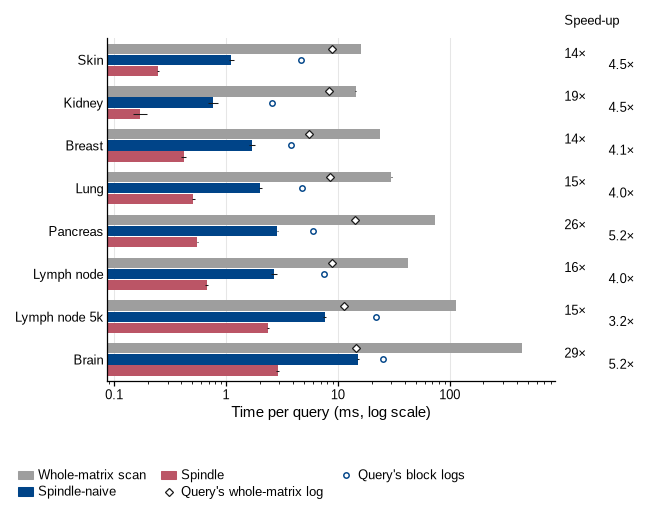

In [2]:
def panel_a(fig):
    W, H = ps.size_mm(fig)
    right = 17.0
    ax = ps.axes(fig, left=17.0, right=right, bottom=ROW_BOTTOM, top=ROW_TOP)
    t = timing
    bh = 0.26
    for i, k in enumerate(KEYS):
        r = t.loc[k]
        for off, col, c in ((-bh, "whole_ms", WHOLE), (0, "naive_ms", NAIVE), (bh, "spindle_ms", SPINDLE)):
            ax.barh(i + off, r[col], height=bh * 0.92, color=c, lw=0, zorder=2)
            ax.errorbar(r[col], i + off, xerr=r[f"{col}_sd"], fmt="none", ecolor=ps.INK, elinewidth=0.5, zorder=3)
        ax.plot(r.qlog_whole_ms, i - bh, "D", ms=2.4, mfc="white", mec=ps.INK, mew=0.6, zorder=4)
        ax.plot(r.qlog_block_ms, i, "o", ms=2.6, mfc="white", mec=NAIVE, mew=0.7, zorder=4)
    ax.set_xscale("log")
    ps.plain_log(ax, "x", subs=(1.0,))
    ps.log_grid(ax, "x")
    ax.set_xlim(min(t.spindle_ms.min(), t.naive_ms.min()) / 2, max(t.whole_ms.max(), t.qlog_whole_ms.max()) * 2)
    rows_axis(ax, True)
    ax.set_xlabel("Time per query (ms, log scale)")
    # speed-ups: whole-matrix scan / Spindle-naive (left), Spindle-naive / Spindle (right)
    tr = blended_transform_factory(fig.transSubfigure, ax.transData)
    x0 = (W - right + 1.5) / W
    x1 = (W - right + 9.0) / W
    for i, k in enumerate(KEYS):
        r = t.loc[k]
        ax.text(x0, i - bh / 2, f"{r.speedup_naive_vs_whole:.0f}×", transform=tr, fontsize=ps.TICK_PT, va="center")
        ax.text(x1, i + bh / 2, f"{r.speedup_spindle_vs_naive:.1f}×", transform=tr, fontsize=ps.TICK_PT, va="center")
    fig.text(x0, 1 - 1.0 / H, "Speed-up", fontsize=ps.TICK_PT, va="top")
    handles = [Patch(color=WHOLE, label="Whole-matrix scan"), Patch(color=NAIVE, label="Spindle-naive"),
               Patch(color=SPINDLE, label="Spindle"),
               Line2D([], [], ls="", marker="D", ms=2.4, mfc="white", mec=ps.INK, mew=0.6, label="Query's whole-matrix log"),
               Line2D([], [], ls="", marker="o", ms=2.6, mfc="white", mec=NAIVE, mew=0.7, label="Query's block logs")]
    fig.legend(handles=handles, ncol=3, loc="lower left", bbox_to_anchor=(2.0 / W, 1.0 / H))


fig = ps.panel(W_A, H_AB)
panel_a(fig)
ps.save_panel(fig, FIG, "A")

## B · Spindle NX at 5 % of N

figures/fig3_whole_tile/panels/B.pdf/.png: 70 x 84 mm, 0.0 / 0.1 MB


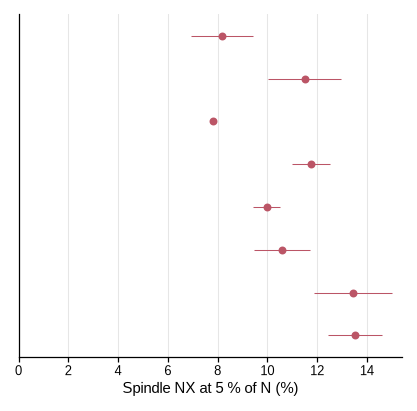

In [3]:
def panel_b(fig):
    ax = ps.axes(fig, left=2.0, right=3.0, bottom=ROW_BOTTOM, top=ROW_TOP)
    t = nx[nx.g == G].set_index("key")
    for i, k in enumerate(KEYS):
        r = t.loc[k]
        ax.errorbar(100 * r.NX5, i, xerr=100 * r.NX5_sd, fmt="o", ms=2.8, color=SPINDLE, elinewidth=0.5, zorder=3)
    rows_axis(ax, False)
    ax.set_xlim(0, None)
    ax.grid(True, axis="x", color="#E6E6E6", linewidth=0.5, zorder=0)
    ax.set_axisbelow(True)
    ax.set_xlabel("Spindle NX at 5 % of N (%)")


fig = ps.panel(W_B, H_AB)
panel_b(fig)
ps.save_panel(fig, FIG, "B")

## C · The typical breast query

figures/fig3_whole_tile/panels/C.pdf/.png: 60 x 64 mm, 0.0 / 0.2 MB


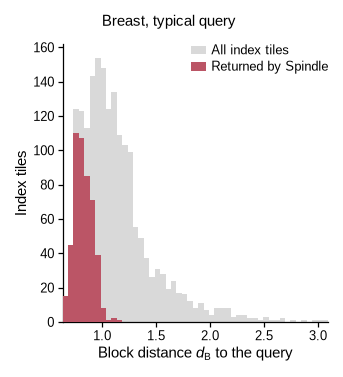

In [4]:
def panel_c(fig):
    W, H = ps.size_mm(fig)
    z = np.load(RES / "band" / "breast_cancer.npz")
    d, found = z["d"], z["found"]
    ax = ps.axes(fig, left=12.0, right=3.0, bottom=11.0, top=6.0)
    bins = np.linspace(d.min(), np.quantile(d, 0.995), 50)
    ax.hist(d, bins=bins, color=ps.LIGHT, lw=0, zorder=2, label="All index tiles")
    ax.hist(d[found], bins=bins, color=SPINDLE, lw=0, zorder=3, label="Returned by Spindle")
    ax.set_xlabel(r"Block distance $d_{\mathcal{B}}$ to the query")
    ax.set_ylabel("Index tiles")
    ax.set_xlim(bins[0], bins[-1])
    ax.legend(loc="upper right")
    fig.text(0.5, 1 - 1.0 / H, "Breast, typical query", ha="center", va="top")


fig = ps.panel(W_C, H_CD)
panel_c(fig)
ps.save_panel(fig, FIG, "C")

## D · Memory against fidelity

figures/fig3_whole_tile/panels/D.pdf/.png: 120 x 64 mm, 0.0 / 0.5 MB


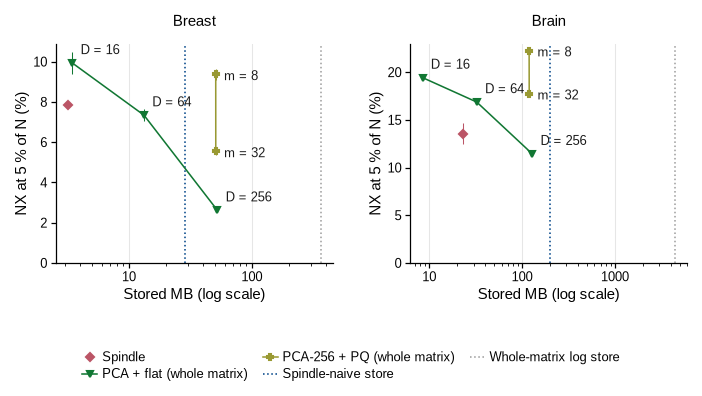

In [5]:
def memory_axes(ax, key):
    m = memory[memory.key == key]
    for meth in ("naive", "whole"):
        ax.axvline(m[m.method == meth].MB.iloc[0], ls=":", lw=0.75, color=NAIVE if meth == "naive" else WHOLE, zorder=1)
    r = m[m.method == "spindle"].iloc[0]
    ax.errorbar(r.MB, 100 * r.NX5, yerr=100 * r.NX5_sd, fmt="D", ms=3.0, color=SPINDLE, elinewidth=0.5, zorder=4)
    for meth, mk in (("pca_flat", "v"), ("pca256_pq", "P")):
        s = m[m.method == meth].assign(v=lambda d: d.param.astype(float)).sort_values("v")
        ax.errorbar(s.MB, 100 * s.NX5, yerr=100 * s.NX5_sd, fmt=f"-{mk}", ms=2.8, color=COMP[meth], elinewidth=0.5,
                    zorder=3)
        for _, q in s.iterrows():
            lab = f"{'D' if meth == 'pca_flat' else 'm'} = {int(q.v)}"
            off = (4, 3) if meth == "pca_flat" else (4, -1)
            ax.annotate(lab, (q.MB, 100 * q.NX5), xytext=off, textcoords="offset points", fontsize=ps.TICK_PT,
                        va="bottom" if meth == "pca_flat" else "center", color=ps.INK)
    ax.set_xscale("log")
    ps.plain_log(ax, "x", subs=(1.0,))
    ps.log_grid(ax, "x")
    ax.set_ylim(0, None)
    ax.set_xlabel("Stored MB (log scale)")
    ax.set_ylabel("NX at 5 % of N (%)")


def panel_d(fig):
    W, H = ps.size_mm(fig)
    for x, key, title in ((10.0, "breast_cancer", "Breast"), (70.0, "brain_cancer", "Brain")):
        ax = ax_mm(fig, x, 21.0, 47.0, H - 27.0)
        memory_axes(ax, key)
        fig.text((x + 23.5) / W, 1 - 1.0 / H, title, ha="center", va="top")
    handles = [Line2D([], [], ls="", marker="D", ms=3.0, color=SPINDLE, label="Spindle"),
               Line2D([], [], marker="v", ms=2.8, color=COMP["pca_flat"], label=COMP_LABEL["pca_flat"]),
               Line2D([], [], marker="P", ms=2.8, color=COMP["pca256_pq"], label=COMP_LABEL["pca256_pq"]),
               Line2D([], [], ls=":", color=NAIVE, label="Spindle-naive store"),
               Line2D([], [], ls=":", color=WHOLE, label="Whole-matrix log store")]
    fig.legend(handles=handles, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0 / H))


fig = ps.panel(W_D, H_CD)
panel_d(fig)
ps.save_panel(fig, FIG, "D")

## Full figure

figures/fig3_whole_tile/fig3_whole_tile.pdf/.png: 180 x 152 mm, 0.0 / 1.3 MB


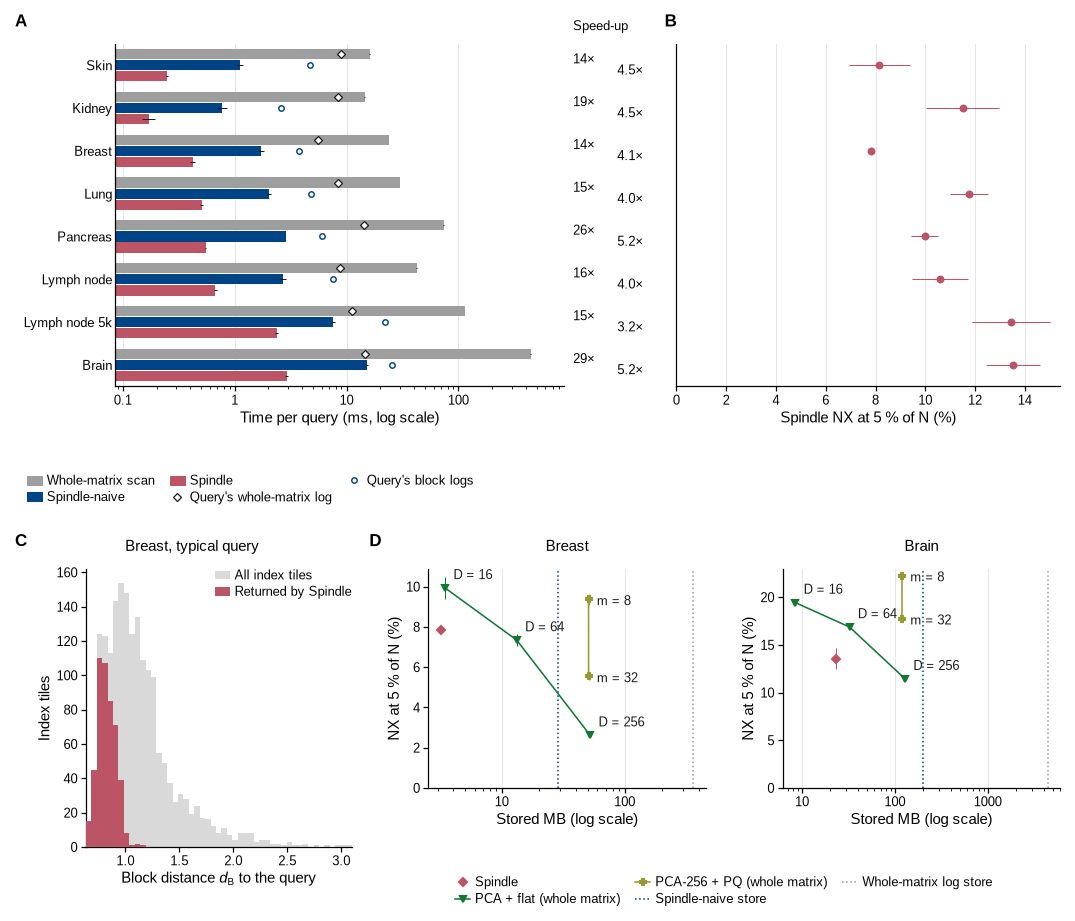

In [6]:
page = ps.page(180, H_AB + 4 + H_CD)
panel_a(ps.place(page, "A", 0, 0, W_A, H_AB))
panel_b(ps.place(page, "B", W_A, 0, W_B, H_AB))
panel_c(ps.place(page, "C", 0, H_AB + 4, W_C, H_CD))
panel_d(ps.place(page, "D", W_C, H_AB + 4, W_D, H_CD))
ps.save_figure(page, FIG)